In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import dblquad

SEED = 2082172357 #seed previded by the RNG
rng = np.random.default_rng(SEED)
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

from mp3lib import sample_mean_cov, is_valid_covariance, gaussian_pdf, whitening_matrix, lmmse_weights


### Validity of the Joint Density

The proposed joint density is

\[
f_{XY}(x,y)=x+y,
\qquad 0\leq x\leq 1,\quad 0\leq y\leq 1.
\]

First, \(f_{XY}(x,y)\geq 0\) throughout the unit square because both \(x\) and \(y\) are nonnegative.

Next, integrate over the entire support:

\[
\begin{aligned}
\int_0^1\int_0^1 (x+y)\,dy\,dx
&=\int_0^1\left[xy+\frac{y^2}{2}\right]_{0}^{1}dx\\
&=\int_0^1\left(x+\frac{1}{2}\right)dx\\
&=\left[\frac{x^2}{2}+\frac{x}{2}\right]_0^1\\
&=1.
\end{aligned}
\]

Since the density is nonnegative and integrates to 1, \(f_{XY}(x,y)\) is a valid joint probability density.

### Deriving the Marginal Densities

The marginal density of \(X\) is found by integrating the joint density over all possible values of \(Y\):

\[
\begin{aligned}
f_X(x)
&=\int_0^1 f_{XY}(x,y)\,dy\\
&=\int_0^1 (x+y)\,dy\\
&=\left[xy+\frac{y^2}{2}\right]_0^1\\
&=x+\frac{1}{2},
\qquad 0\leq x\leq 1.
\end{aligned}
\]

Therefore,

\[
f_X(x)=
\begin{cases}
x+\frac{1}{2}, & 0\leq x\leq 1,\\
0, & \text{otherwise}.
\end{cases}
\]

The marginal density of \(Y\) is found by integrating the joint density over all possible values of \(X\):

\[
\begin{aligned}
f_Y(y)
&=\int_0^1 f_{XY}(x,y)\,dx\\
&=\int_0^1 (x+y)\,dx\\
&=\left[\frac{x^2}{2}+xy\right]_0^1\\
&=y+\frac{1}{2},
\qquad 0\leq y\leq 1.
\end{aligned}
\]

Therefore,

\[
f_Y(y)=
\begin{cases}
y+\frac{1}{2}, & 0\leq y\leq 1,\\
0, & \text{otherwise}.
\end{cases}
\]

Numerical integral of joint density = 1.00000000
Maximum error in f_X(x) = 2.22044605e-16
Maximum error in f_Y(y) = 8.88178420e-16
f_X(0.3) = 0.80000000
f_Y|X(0.3|0.3) = 0.75000000
Integral of conditional density = 1.00000000

Numerical quadrature values:
E[X] = 0.58333333
E[Y] = 0.58333333
E[XY] = 0.33333333
Var(X) = 0.07638889
Var(Y) = 0.07638889
Cov(X,Y) = -0.00694444
Correlation = -0.09090909

Number of accepted samples = 1,000,000
Number of proposed samples = 2,200,000
Acceptance rate = 0.50006318

Rejection-sampling results:
E[X]          : estimate = 0.58335089, exact = 0.58333333, difference = 1.75576173e-05, SE = 2.65272657e-04
E[Y]          : estimate = 0.58354161, exact = 0.58333333, difference = 2.08279570e-04, SE = 2.62972992e-04
E[XY]         : estimate = 0.33341825, exact = 0.33333333, difference = 8.49121844e-05, SE = 2.37179142e-04
Var(X)        : estimate = 0.07642236, exact = 0.07638889, difference = 3.34727946e-05, SE = 6.72956144e-05
Var(Y)        : estimate = 0.07

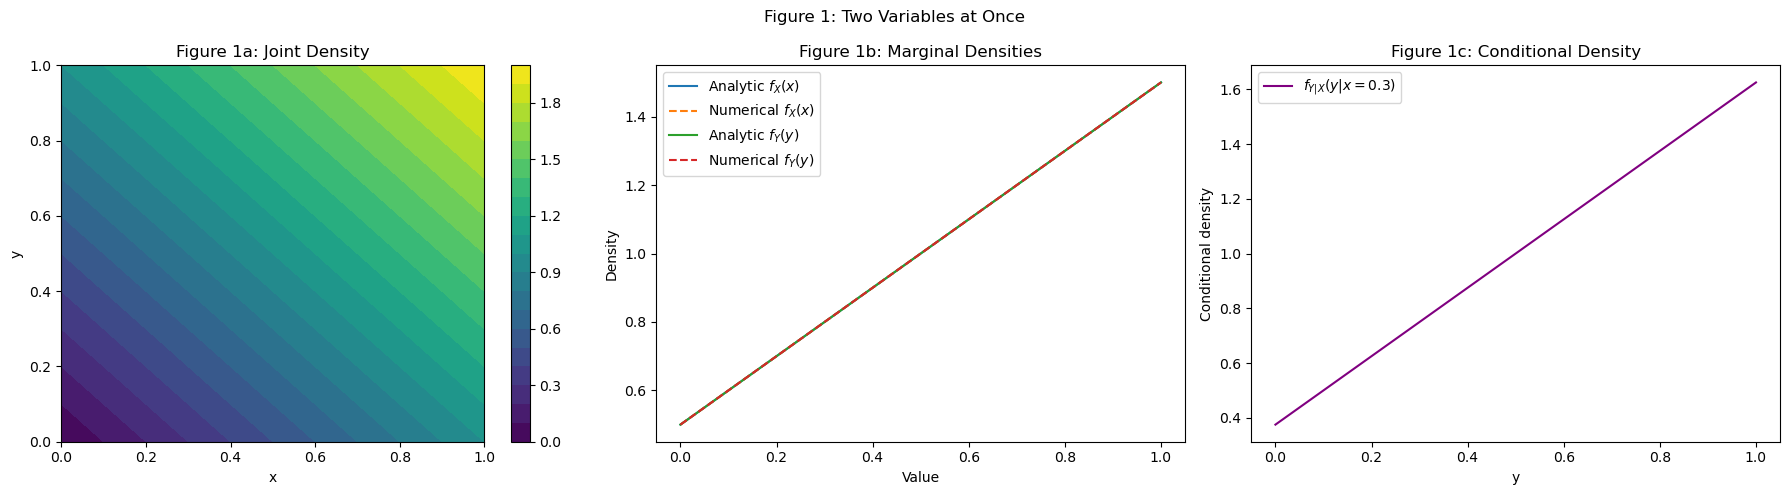

Summary of Figure 1:
The joint density increases toward the upper-right because f_XY(x,y) = x + y.
The analytical and numerical marginal densities overlap, showing that the numerical integration is accurate.
The conditional density f_Y|X(y|x = 0.3) increases linearly with y, and
the conditional density integrates to 1, as required for a valid probability density.
The density has diagonal contours, so after accounting for the marginals, larger values of X are paired with slightly smaller values of Y.
This causes a weak negative covariance and makes X and Y pull against each other slightly.


In [60]:
# Step 1: Two variables at once

# Joint density: f_XY(x,y) = x + y, 0 <= x <= 1, 0 <= y <= 1

def joint_pdf(x, y):
    inside = (0 <= x) & (x <= 1) & (0 <= y) & (y <= 1)
    return np.where(inside, x + y, 0.0)


def marginal_x_analytic(x):
    return np.where((0 <= x) & (x <= 1), x + 0.5, 0.0)


def marginal_y_analytic(y):
    return np.where((0 <= y) & (y <= 1), y + 0.5, 0.0)


def conditional_y_given_x(y, x_value):
    return np.where(
        (0 <= y) & (y <= 1),
        (x_value + y) / (x_value + 0.5),
        0.0
    )


# density 
total_probability = dblquad(
    lambda y, x: joint_pdf(x, y),
    0, 1,
    lambda x: 0,
    lambda x: 1
)[0]

print(f"Numerical integral of joint density = {total_probability:.8f}")


x_grid = np.linspace(0, 1, 501)
y_grid = np.linspace(0, 1, 501)

joint_grid = joint_pdf(
    x_grid[:, None],
    y_grid[None, :]
)

marginal_x_numerical = np.trapezoid(
    joint_grid,
    y_grid,
    axis=1
)

marginal_y_numerical = np.trapezoid(
    joint_grid,
    x_grid,
    axis=0
)

print(
    f"Maximum error in f_X(x) = "
    f"{np.max(np.abs(marginal_x_numerical - marginal_x_analytic(x_grid))):.8e}"
)

print(
    f"Maximum error in f_Y(y) = "
    f"{np.max(np.abs(marginal_y_numerical - marginal_y_analytic(y_grid))):.8e}"
)


# ------------------------------------------------------------
# Conditional density
# ------------------------------------------------------------

x_value = 0.3

conditional_density = conditional_y_given_x(
    y_grid,
    x_value
)

print(
    f"f_X(0.3) = "
    f"{marginal_x_analytic(np.array([0.3]))[0]:.8f}"
)

print(
    f"f_Y|X(0.3|0.3) = "
    f"{conditional_y_given_x(np.array([0.3]), x_value)[0]:.8f}"
)

print(
    f"Integral of conditional density = "
    f"{np.trapezoid(conditional_density, y_grid):.8f}"
)


# ------------------------------------------------------------
# Analytical and numerical moments
# ------------------------------------------------------------

exact_statistics = np.array([
    7 / 12,       # E[X]
    7 / 12,       # E[Y]
    1 / 3,        # E[XY]
    11 / 144,     # Var(X)
    11 / 144,     # Var(Y)
    -1 / 144,     # Cov(X,Y)
    -1 / 11       # Correlation
])

labels = [
    "E[X]",
    "E[Y]",
    "E[XY]",
    "Var(X)",
    "Var(Y)",
    "Cov(X,Y)",
    "Correlation"
]


def integrate_joint(function):
    return dblquad(
        lambda y, x: function(x, y) * joint_pdf(x, y),
        0, 1,
        lambda x: 0,
        lambda x: 1
    )[0]


EX = integrate_joint(lambda x, y: x)
EY = integrate_joint(lambda x, y: y)
EXY = integrate_joint(lambda x, y: x * y)

EX2 = integrate_joint(lambda x, y: x**2)
EY2 = integrate_joint(lambda x, y: y**2)

VAR_X = EX2 - EX**2
VAR_Y = EY2 - EY**2
COV_XY = EXY - EX * EY
CORR_XY = COV_XY / np.sqrt(VAR_X * VAR_Y)

numerical_statistics = np.array([
    EX,
    EY,
    EXY,
    VAR_X,
    VAR_Y,
    COV_XY,
    CORR_XY
])

print("\nNumerical quadrature values:")

for label, value in zip(labels, numerical_statistics):
    print(f"{label} = {value:.8f}")


# pt 5 - rejection sampling

number_of_samples = 1_000_000
accepted_points = []
number_proposed = 0
number_accepted = 0

while number_accepted < number_of_samples:

    batch_size = 200_000

    proposal = rng_step1.random((batch_size, 2))
    x_proposal = proposal[:, 0]
    y_proposal = proposal[:, 1]

    acceptance_probability = (
        x_proposal + y_proposal
    ) / 2

    accepted = (
        rng_step1.random(batch_size)
        < acceptance_probability
    )

    accepted_batch = proposal[accepted]

    accepted_points.append(accepted_batch)
    number_accepted += accepted_batch.shape[0]
    number_proposed += batch_size

samples = np.vstack(accepted_points)[:number_of_samples]

print(
    f"\nNumber of accepted samples = "
    f"{samples.shape[0]:,}"
)

print(
    f"Number of proposed samples = "
    f"{number_proposed:,}"
)

print(
    f"Acceptance rate = "
    f"{number_accepted / number_proposed:.8f}"
)


def calculate_statistics(data):
    x = data[:, 0]
    y = data[:, 1]

    return np.array([
        np.mean(x),
        np.mean(y),
        np.mean(x * y),
        np.var(x, ddof=1),
        np.var(y, ddof=1),
        np.cov(x, y, ddof=1)[0, 1],
        np.corrcoef(x, y)[0, 1]
    ])


sample_statistics = calculate_statistics(samples)

number_of_batches = 100
batches = np.array_split(samples, number_of_batches)

batch_statistics = np.array([
    calculate_statistics(batch)
    for batch in batches
])

standard_errors = (
    np.std(batch_statistics, axis=0, ddof=1)
    / np.sqrt(number_of_batches)
)

print("\nRejection-sampling results:")

for label, estimate, exact, standard_error in zip(
    labels,
    sample_statistics,
    exact_statistics,
    standard_errors
):
    print(
        f"{label:14s}: "
        f"estimate = {estimate:.8f}, "
        f"exact = {exact:.8f}, "
        f"difference = {estimate - exact:.8e}, "
        f"SE = {standard_error:.8e}"
    )


X_plot, Y_plot = np.meshgrid(x_grid, y_grid)
Z_plot = joint_pdf(X_plot, Y_plot)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# Joint density
contour = axes[0].contourf(
    X_plot,
    Y_plot,
    Z_plot,
    levels=20,
    cmap="viridis"
)

fig.colorbar(contour, ax=axes[0])
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Figure 1a: Joint Density")


# Marginal densities
axes[1].plot(
    x_grid,
    marginal_x_analytic(x_grid),
    label="Analytic $f_X(x)$"
)

axes[1].plot(
    x_grid,
    marginal_x_numerical,
    "--",
    label="Numerical $f_X(x)$"
)

axes[1].plot(
    y_grid,
    marginal_y_analytic(y_grid),
    label="Analytic $f_Y(y)$"
)

axes[1].plot(
    y_grid,
    marginal_y_numerical,
    "--",
    label="Numerical $f_Y(y)$"
)

axes[1].set_xlabel("Value")
axes[1].set_ylabel("Density")
axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].legend()


# Conditional density
axes[2].plot(
    y_grid,
    conditional_density,
    color="purple",
    label="$f_{Y|X}(y|x=0.3)$"
)

axes[2].set_xlabel("y")
axes[2].set_ylabel("Conditional density")
axes[2].set_title("Figure 1c: Conditional Density")
axes[2].legend()

plt.suptitle("Figure 1: Two Variables at Once")
plt.tight_layout()
plt.show()


# Interpretation
print(f"Summary of Figure 1:")
print(f"The joint density increases toward the upper-right because f_XY(x,y) = x + y.")
print(f"The analytical and numerical marginal densities overlap, showing that the numerical integration is accurate.")
print(f"The conditional density f_Y|X(y|x = 0.3) increases linearly with y, and")
print(f"the conditional density integrates to 1, as required for a valid probability density.")
print(f"The density has diagonal contours, so after accounting for the marginals, larger values of X are paired with slightly smaller values of Y.")
print(f"This causes a weak negative covariance and makes X and Y pull against each other slightly.")

### Covariance of \(X\) and \(Y=X^2\)

Let

$$
X \sim \operatorname{Uniform}(-1,1),
\qquad
Y=X^2.
$$

The probability density of \(X\) is

$$
f_X(x)=\frac{1}{2},
\qquad -1\leq x\leq 1.
$$

First,

$$
E[X]
=
\int_{-1}^{1} x\frac{1}{2}\,dx
=
0.
$$

Also,

$$
E[Y]
=
E[X^2]
=
\int_{-1}^{1} x^2\frac{1}{2}\,dx
=
\frac{1}{3}.
$$

Finally,

$$
E[XY]
=
E[X^3]
=
\int_{-1}^{1} x^3\frac{1}{2}\,dx
=
0.
$$

The covariance is therefore

$$
\begin{aligned}
\operatorname{Cov}(X,Y)
&=E[XY]-E[X]E[Y]\\
&=0-(0)\left(\frac{1}{3}\right)\\
&=0.
\end{aligned}
$$

Thus, \(X\) and \(Y=X^2\) are uncorrelated, even though \(Y\) is completely determined by \(X\).

Analytical Cov(X,Y) = 0.00000000
Sample correlation = -2.87385721e-05
Correlation standard error = 4.05824201e-04
Correlation measures only linear dependence.
For Y = X^2, the relationship is nonlinear, so positive and negative X values cancel and produce zero correlation.
However, Y is still completely determined by X, so the variables are dependent.
Maximum binned conditional variance = 1.31644232e-04
Mean binned conditional variance = 4.44695484e-05


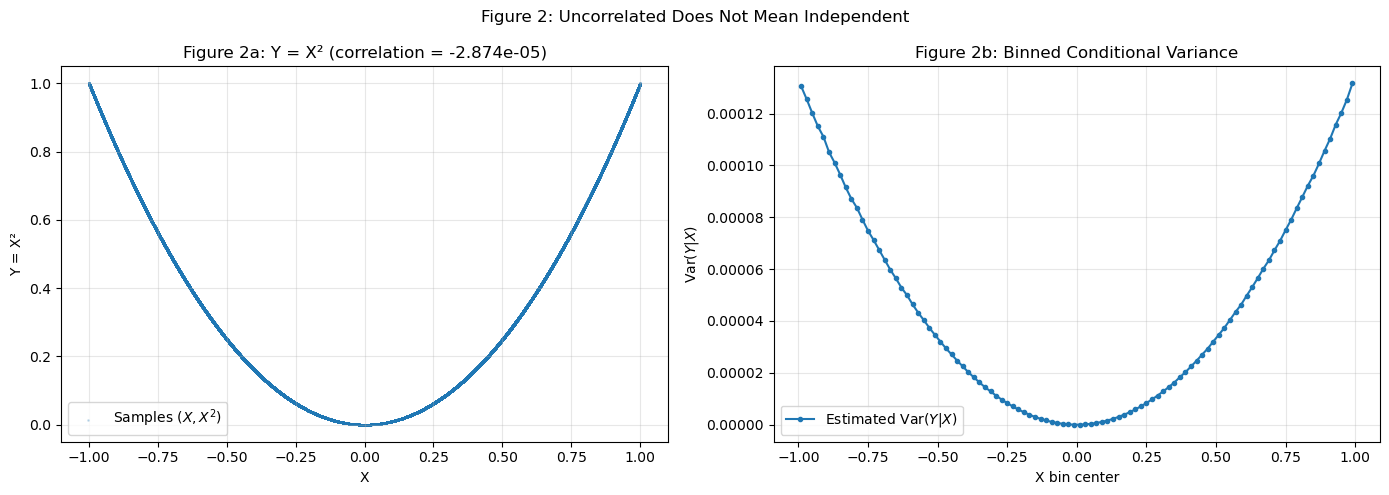

Figure 2 summary:
The scatter plot shows the nonlinear relationship Y = X², even though the correlation is nearly zero.
The small binned conditional variances show that knowing X almost completely determines Y.

Gaussian joint/product Frobenius difference = 3.59280719e-02

For jointly Gaussian variables, zero correlation causes the joint density to factor into the marginal densities.
Therefore, uncorrelated jointly Gaussian variables are independent.
In general, nonlinear dependence can exist even when correlation is zero.
This makes the Gaussian assumption important because many engineering methods rely only on means and covariances.


In [61]:
# Step 2: Uncorrelated does not mean independent

number_of_samples_step2 = 10_000_000

# X is Uniform(-1,1), and Y is completely determined by X
x_step2 = rng_step2.uniform(
    -1,
    1,
    number_of_samples_step2
)

y_step2 = x_step2**2


# ------------------------------------------------------------
# Covariance and correlation
# ------------------------------------------------------------

print(f"Analytical Cov(X,Y) = {0.0:.8f}")

sample_correlation_step2 = np.corrcoef(
    x_step2,
    y_step2
)[0, 1]

# Estimate the correlation standard error using batches
number_of_batches_step2 = 100

batch_correlations_step2 = []

for x_batch, y_batch in zip(
    np.array_split(x_step2, number_of_batches_step2),
    np.array_split(y_step2, number_of_batches_step2)
):
    batch_correlations_step2.append(
        np.corrcoef(x_batch, y_batch)[0, 1]
    )

correlation_standard_error_step2 = (
    np.std(batch_correlations_step2, ddof=1)
    / np.sqrt(number_of_batches_step2)
)

print(
    f"Sample correlation = "
    f"{sample_correlation_step2:.8e}"
)

print(
    f"Correlation standard error = "
    f"{correlation_standard_error_step2:.8e}"
)

print(f"Correlation measures only linear dependence.")
print(f"For Y = X^2, the relationship is nonlinear, so positive and negative X values cancel and produce zero correlation.")
print(f"However, Y is still completely determined by X, so the variables are dependent.")


# ------------------------------------------------------------
# Binned conditional variance
# ------------------------------------------------------------

number_of_bins_step2 = 100

bin_edges_step2 = np.linspace(
    -1,
    1,
    number_of_bins_step2 + 1
)

bin_centers_step2 = (
    bin_edges_step2[:-1]
    + bin_edges_step2[1:]
) / 2

conditional_variances_step2 = []

for lower_edge, upper_edge in zip(
    bin_edges_step2[:-1],
    bin_edges_step2[1:]
):
    in_bin = (
        (x_step2 >= lower_edge)
        & (x_step2 < upper_edge)
    )

    conditional_variances_step2.append(
        np.var(y_step2[in_bin], ddof=1)
    )

conditional_variances_step2 = np.array(
    conditional_variances_step2
)

print(
    f"Maximum binned conditional variance = "
    f"{np.max(conditional_variances_step2):.8e}"
)

print(
    f"Mean binned conditional variance = "
    f"{np.mean(conditional_variances_step2):.8e}"
)


# ------------------------------------------------------------
# Figure 2
# ------------------------------------------------------------

plot_size_step2 = 100_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].scatter(
    x_step2[:plot_size_step2],
    y_step2[:plot_size_step2],
    s=1,
    alpha=0.2,
    label=r"Samples $(X,X^2)$"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y = X²")

axes[0].set_title(
    f"Figure 2a: Y = X² "
    f"(correlation = {sample_correlation_step2:.3e})"
)

axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].plot(
    bin_centers_step2,
    conditional_variances_step2,
    "o-",
    markersize=3,
    label=r"Estimated $\operatorname{Var}(Y|X)$"
)

axes[1].set_xlabel("X bin center")
axes[1].set_ylabel(r"$\operatorname{Var}(Y|X)$")
axes[1].set_title("Figure 2b: Binned Conditional Variance")

axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Figure 2: Uncorrelated Does Not Mean Independent")
plt.tight_layout()
plt.show()


print(f"Figure 2 summary:")
print(f"The scatter plot shows the nonlinear relationship Y = X², even though the correlation is nearly zero.")
print(f"The small binned conditional variances show that knowing X almost completely determines Y.\n")


# ------------------------------------------------------------
# Gaussian comparison
# ------------------------------------------------------------

gaussian_samples_step2 = rng_step2.standard_normal(
    (1_000_000, 2)
)

gaussian_x_step2 = gaussian_samples_step2[:, 0]
gaussian_y_step2 = gaussian_samples_step2[:, 1]

histogram_edges_step2 = np.linspace(-4, 4, 51)

joint_density_step2, _, _ = np.histogram2d(
    gaussian_x_step2,
    gaussian_y_step2,
    bins=[histogram_edges_step2, histogram_edges_step2],
    density=True
)

x_density_step2, _ = np.histogram(
    gaussian_x_step2,
    bins=histogram_edges_step2,
    density=True
)

y_density_step2, _ = np.histogram(
    gaussian_y_step2,
    bins=histogram_edges_step2,
    density=True
)

product_of_marginals_step2 = np.outer(
    x_density_step2,
    y_density_step2
)

gaussian_difference_step2 = np.linalg.norm(
    joint_density_step2
    - product_of_marginals_step2
)

print(
    f"Gaussian joint/product Frobenius difference = "
    f"{gaussian_difference_step2:.8e}"
)


# Step 6 explanation

print(f"\nFor jointly Gaussian variables, zero correlation causes the joint density to factor into the marginal densities.")
print(f"Therefore, uncorrelated jointly Gaussian variables are independent.")
print(f"In general, nonlinear dependence can exist even when correlation is zero.")
print(f"This makes the Gaussian assumption important because many engineering methods rely only on means and covariances.")

Sigma is symmetric? True
Sigma is valid? True
Eigenvalues of Sigma: [1.26487889 1.78819531 3.09808432 7.84884147]
Determinant of Sigma: 55.0000
Non-symmetric matrix is valid? False
Matrix with a negative eigenvalue is valid? False

Single-draw errors:
N = 100, Frobenius error = 0.624151
N = 1,000, Frobenius error = 0.485810
N = 10,000, Frobenius error = 0.127057
N = 100,000, Frobenius error = 0.039803
N = 1,000,000, Frobenius error = 0.016319

Averaged errors:
N = 100, average error = 1.581010, SE = 0.037133, error*sqrt(N) = 15.810099
N = 1,000, average error = 0.519180, SE = 0.011916, error*sqrt(N) = 16.417905
N = 10,000, average error = 0.148900, SE = 0.005162, error*sqrt(N) = 14.889955
N = 100,000, average error = 0.048895, SE = 0.003656, error*sqrt(N) = 15.461875
N = 1,000,000, average error = 0.015469, SE = 0.001624, error*sqrt(N) = 15.469043

Fitted slope = -0.5045
Expected slope = -0.5000


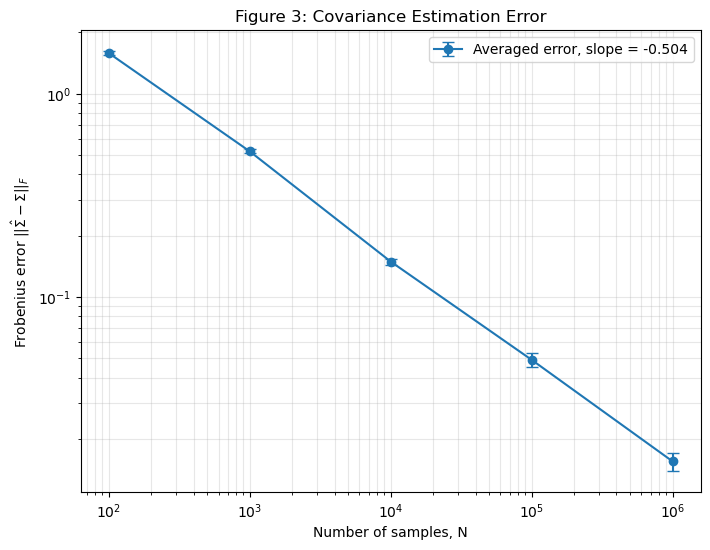


Number of free covariance parameters:
d = 4: 10
d = 100: 5050
Estimated samples needed for d = 100: 5,050,000
A radar with 100 array elements needs to estimate 5,050 covariance parameters.
This requires many snapshots, and a poor estimate can cause inaccurate beamforming and unstable detection.
One solution is to use shrinkage or diagonal loading, which improves the covariance estimate when data is limited.


In [62]:
# Step 3: The covariance matrix and how well you can estimate it

# 1 - Confirm sigma is a valid covariance matrix
Sigma = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mean = np.zeros(4)


eigenvalues = np.linalg.eigh(Sigma)[0]
determinant = np.linalg.det(Sigma)

non_symmetric = np.array([
    [1, 2],
    [0, 1]
])

negative_eigenvalue = np.array([
    [1, 0],
    [0, -1]
])

print(f"Sigma is symmetric? {np.allclose(Sigma, Sigma.T)}")
print(f"Sigma is valid? {is_valid_covariance(Sigma)}")
print(f"Eigenvalues of Sigma: {eigenvalues}")
print(f"Determinant of Sigma: {determinant:.4f}")

print(
    f"Non-symmetric matrix is valid? "
    f"{is_valid_covariance(non_symmetric)}"
)

print(
    f"Matrix with a negative eigenvalue is valid? "
    f"{is_valid_covariance(negative_eigenvalue)}"
)


# Step 2 - generate samples with this covariance
sample_sizes = np.array([
    10**2,
    10**3,
    10**4,
    10**5,
    10**6
])

single_errors = []

for N in sample_sizes:
    samples = rng_step3.multivariate_normal(
        mean,
        Sigma,
        size=N
    )

    _, estimated_covariance = sample_mean_cov(samples)

    error = np.linalg.norm(
        estimated_covariance - Sigma,
        ord="fro"
    )

    single_errors.append(error)

single_errors = np.array(single_errors)

print("\nSingle-draw errors:")

for N, error in zip(sample_sizes, single_errors):
    print(
        f"N = {N:,}, "
        f"Frobenius error = {error:.6f}"
    )


# Step 3 - repeated many times

repetitions = [
    200,
    200,
    100,
    30,
    10
]

average_errors = []
standard_errors = []

for N, number_of_repetitions in zip(
    sample_sizes,
    repetitions
):
    errors = []

    for repetition in range(number_of_repetitions):
        samples = rng_step3.multivariate_normal(
            mean,
            Sigma,
            size=N
        )

        _, estimated_covariance = sample_mean_cov(samples)

        error = np.linalg.norm(
            estimated_covariance - Sigma,
            ord="fro"
        )

        errors.append(error)

    errors = np.array(errors)

    average_errors.append(
        np.mean(errors)
    )

    standard_errors.append(
        np.std(errors, ddof=1)
        / np.sqrt(number_of_repetitions)
    )

average_errors = np.array(average_errors)
standard_errors = np.array(standard_errors)


# Step 4 - repeat and plot 

slope, intercept = np.polyfit(
    np.log10(sample_sizes),
    np.log10(average_errors),
    1
)

scaled_errors = average_errors * np.sqrt(sample_sizes)

print("\nAveraged errors:")

for N, average_error, standard_error, scaled_error in zip(
    sample_sizes,
    average_errors,
    standard_errors,
    scaled_errors
):
    print(
        f"N = {N:,}, "
        f"average error = {average_error:.6f}, "
        f"SE = {standard_error:.6f}, "
        f"error*sqrt(N) = {scaled_error:.6f}"
    )

print(f"\nFitted slope = {slope:.4f}")
print(f"Expected slope = {-0.5:.4f}")


plt.figure(figsize=(8, 6))

plt.errorbar(
    sample_sizes,
    average_errors,
    yerr=standard_errors,
    fmt="o-",
    capsize=4,
    label=f"Averaged error, slope = {slope:.3f}"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of samples, N")
plt.ylabel(r"Frobenius error $||\hat{\Sigma}-\Sigma||_F$")
plt.title("Figure 3: Covariance Estimation Error")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.show()


#step 5 - number of free covariance parameters

parameters_d4 = 4 * (4 + 1) // 2
parameters_d100 = 100 * (100 + 1) // 2

estimated_samples_d100 = (
    10**4 * parameters_d100 / parameters_d4
)

print("\nNumber of free covariance parameters:")
print(f"d = 4: {parameters_d4}")
print(f"d = 100: {parameters_d100}")

print(
    f"Estimated samples needed for d = 100: "
    f"{estimated_samples_d100:,.0f}"
)

# Step 6 question
print(f"A radar with 100 array elements needs to estimate 5,050 covariance parameters.")
print(f"This requires many snapshots, and a poor estimate can cause inaccurate beamforming and unstable detection.")
print(f"One solution is to use shrinkage or diagonal loading, which improves the covariance estimate when data is limited.")